# EDA Check-in: Dual Types and Base Stat Totals in Pokémon

Research question: do dual-type Pokémon have higher base stat totals than
single-type Pokémon?

H0: type count has no relationship with base stat total.
H1: dual-type Pokémon have a higher mean base stat total.

Data: `pokemon.csv` (armgilles GitHub Gist), Generations 1–6.

## 1. Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

df = pd.read_csv("pokemon.csv")
df.head()

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False


## 2. Structure of the data

In [2]:
print("Rows, columns:", df.shape)
df.dtypes

Rows, columns: (800, 13)


#              int64
Name          object
Type 1        object
Type 2        object
Total          int64
HP             int64
Attack         int64
Defense        int64
Sp. Atk        int64
Sp. Def        int64
Speed          int64
Generation     int64
Legendary       bool
dtype: object

In [3]:
df.isna().sum()

#               0
Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

`Type 2` is blank for single-type Pokémon. These blanks carry meaning and
are not errors, so they are kept and used to build the type-count variable.

In [4]:
dupes = df["#"].duplicated(keep=False)
print("Rows sharing a Pokédex number:", dupes.sum())
df.loc[dupes, ["#", "Name", "Type 1", "Type 2", "Total"]].head(10)

Rows sharing a Pokédex number: 144


,#,Name,Type 1,Type 2,Total
2,3,Venusaur,Grass,Poison,525
3,3,VenusaurMega Venusaur,Grass,Poison,625
6,6,Charizard,Fire,Flying,534
7,6,CharizardMega Charizard X,Fire,Dragon,634
8,6,CharizardMega Charizard Y,Fire,Flying,634
11,9,Blastoise,Water,NaN,530
12,9,BlastoiseMega Blastoise,Water,NaN,630
18,15,Beedrill,Bug,Poison,395
19,15,BeedrillMega Beedrill,Bug,Poison,495
22,18,Pidgeot,Normal,Flying,479


Some Pokédex numbers repeat because Mega Evolutions and alternate forms
have their own rows. Each form has its own stats, so each row is kept.

## 3. Checking the Total column

In [5]:
stat_cols = ["HP", "Attack", "Defense", "Sp. Atk", "Sp. Def", "Speed"]
mismatch = (df[stat_cols].sum(axis=1) != df["Total"]).sum()
print("Rows where Total does not equal the sum of the six stats:", mismatch)

Rows where Total does not equal the sum of the six stats: 0


## 4. Creating the type-count variable

In [6]:
df["Dual Type"] = df["Type 2"].notna()
df["Type Count"] = np.where(df["Dual Type"], "Dual", "Single")
df["Type Count"].value_counts()

Type Count
Dual      414
Single    386
Name: count, dtype: int64

## 5. Summary statistics

In [7]:
df[stat_cols + ["Total"]].describe().round(1)

,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Total
count,800.0,800.0,800.0,800.0,800.0,800.0,800.0
mean,69.3,79.0,73.8,72.8,71.9,68.3,435.1
std,25.5,32.5,31.2,32.7,27.8,29.1,120.0
min,1.0,5.0,5.0,10.0,20.0,5.0,180.0
25%,50.0,55.0,50.0,49.8,50.0,45.0,330.0
50%,65.0,75.0,70.0,65.0,70.0,65.0,450.0
75%,80.0,100.0,90.0,95.0,90.0,90.0,515.0
max,255.0,190.0,230.0,194.0,230.0,180.0,780.0


In [8]:
df.groupby("Type Count")["Total"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Type Count,,,,,,,,
Dual,414.0,456.6,120.8,190.0,355.0,475.0,529.5,780.0
Single,386.0,412.0,114.7,180.0,313.2,410.0,495.0,780.0


## 6. Distribution of Total by type count

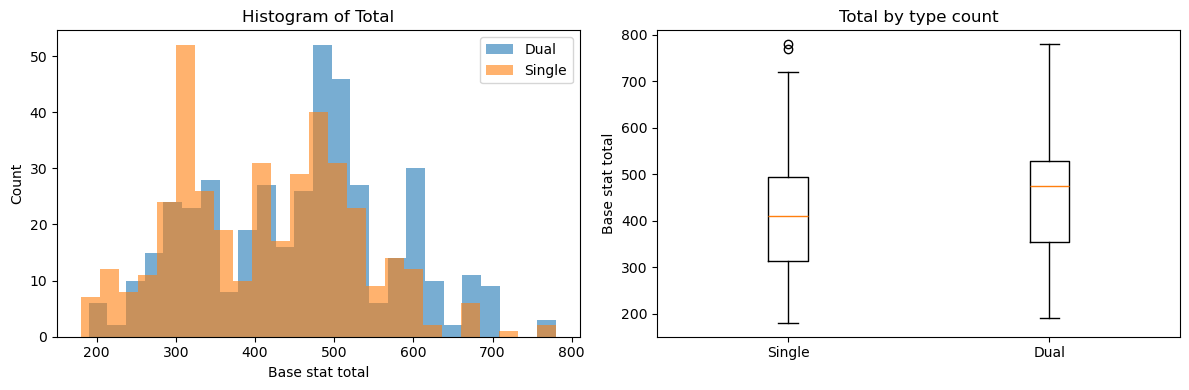

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, group in df.groupby("Type Count"):
	axes[0].hist(group["Total"], bins=25, alpha=0.6, label=label)
axes[0].set_xlabel("Base stat total")
axes[0].set_ylabel("Count")
axes[0].set_title("Histogram of Total")
axes[0].legend()

single = df.loc[~df["Dual Type"], "Total"]
dual = df.loc[df["Dual Type"], "Total"]
axes[1].boxplot([single, dual])
axes[1].set_xticks([1, 2], ["Single", "Dual"])
axes[1].set_ylabel("Base stat total")
axes[1].set_title("Total by type count")

plt.tight_layout()
plt.show()

## 7. Possible confounders: Legendary status and generation

In [10]:
pd.crosstab(df["Type Count"], df["Legendary"], margins=True)

Legendary,False,True,All
Type Count,,,
Dual,374,40,414
Single,361,25,386
All,735,65,800


In [11]:
df.groupby(["Legendary", "Type Count"])["Total"].agg(["count", "mean",
													  "median"]).round(1)

count   mean  median
Legendary Type Count                      
False     Dual          374  436.5   460.0
          Single        361  397.3   405.0
True      Dual           40  645.2   630.0
          Single         25  624.8   600.0

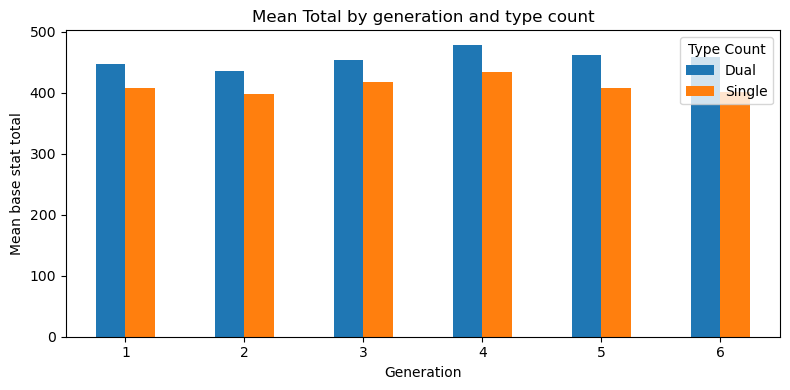

In [12]:
gen = df.groupby(["Generation", "Type Count"])["Total"].mean().unstack()
gen.plot(kind="bar", figsize=(8, 4))
plt.ylabel("Mean base stat total")
plt.title("Mean Total by generation and type count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
pd.crosstab(df["Generation"], df["Type Count"], normalize="index").round(2)

Type Count,Dual,Single
Generation,,
1,0.47,0.53
2,0.52,0.48
3,0.51,0.49
4,0.55,0.45
5,0.50,0.50
6,0.61,0.39


## 8. Observed difference with and without Legendary Pokémon

In [14]:
def mean_diff(data):
	means = data.groupby("Type Count")["Total"].mean()
	return means["Dual"] - means["Single"]


non_legendary = df[~df["Legendary"]]
print("Dual minus single, all Pokémon:", round(mean_diff(df), 1))
print("Dual minus single, non-Legendary:", round(mean_diff(non_legendary), 1))

Dual minus single, all Pokémon: 44.6
Dual minus single, non-Legendary: 39.2


## 9. Which types appear most often

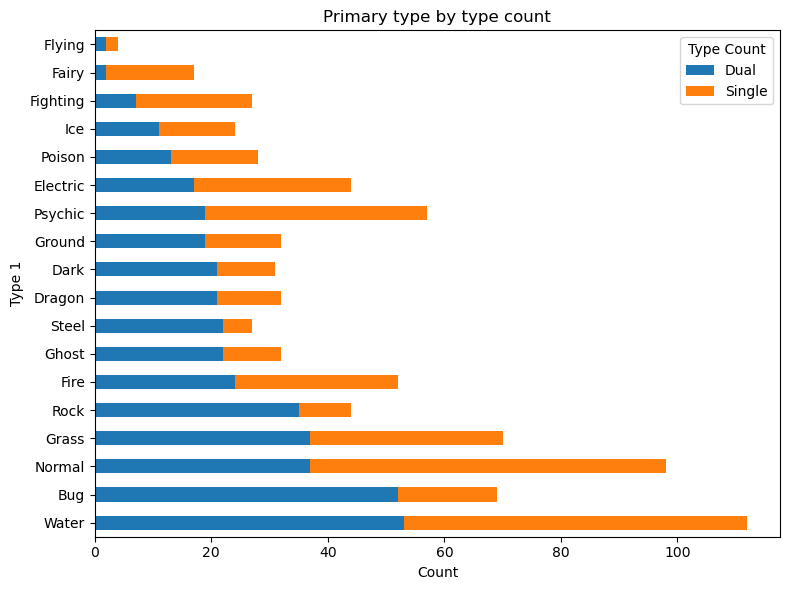

In [15]:
type1 = df.groupby(["Type 1", "Type Count"]).size().unstack(fill_value=0)
type1.sort_values("Dual", ascending=False).plot(kind="barh", stacked=True,
												figsize=(8, 6))
plt.xlabel("Count")
plt.title("Primary type by type count")
plt.tight_layout()
plt.show()

## 10. Notes for the next stage

- Summarise here what the plots and tables show about Single and Dual totals.
- Note whether the difference holds after removing Legendary Pokémon.
- Next steps: permutation test on the difference in mean Total, bootstrap
  intervals for the difference in means and medians, and a check of the
  data against PokéAPI.